# Crypto Portfolio V2 — Binance 1-minute data + Walk-Forward + CEBRA / LightGBM

**Google Colab | 5 Spot pairs:** BTCUSDT, ETHUSDT, SOLUSDT, BNBUSDT, XRPUSDT.

این نوت‌بوک **مستقل** است: سلول‌ها را به ترتیب از اول اجرا کن. هیچ متغیر یا فایل اجباری از نسخه قبلی نیاز نیست.

**هدف:** پیش‌بینی بازده ۷روزه، تخصیص سرمایه هر هفته (دوشنبه ۰۰:۰۰ UTC)، هزینه خرید/فروش، نمودار ارزش سرمایه با شروع ۱۰۰ دلار، مقایسه سه مدل و سه معیار ساده.

- **داده واقعاً ۱دقیقه‌ای دانلود و پردازش می‌شود**؛ اما برای کارایی Colab، سیگنال‌های دقیقه‌ای در ویژگی‌های روزانه (نوسان محقق‌شده دقیقه‌ای، شوک حجم، فشار خرید، جهش، و...) خلاصه می‌شوند. **CEBRA و LightGBM مستقیماً روی همه میلیون‌ها ردیف دقیقه‌ای fit نمی‌شوند**؛ هر دو روی بردارهای ویژگیِ مشتق‌شده از داده دقیقه‌ای آموزش می‌بینند. این نکته تفاوت مهمی با مدل ۱دقیقه‌ایِ پیش‌بینی در هر دقیقه دارد.
- برای **هر نماد، اولین ماه موجود در آرشیو Spot Binance** به شکل خودکار شناسایی می‌شود؛ داده قدیمی BTC/ETH به دلیل عرضه دیرتر SOL حذف نمی‌شود. ویژگی `listed` برای ارزهای هنوز عرضه‌نشده به‌کار می‌رود؛ هیچ قیمت قبل از عرضه جعل نمی‌شود.
- **Walk-forward فصلی**: مدل‌ها در شروع هر فصل فقط از گذشته مجاز آموزش می‌بینند و در همان فصل، هر هفته پیش‌بینی تازه صادر می‌کنند. وزن‌ها هفتگی تغییر می‌کنند، مدل‌ها فصلی بازآموزی می‌شوند.
- آزمایش مدل‌ها: **LightGBM-only**, **CEBRA-Time + Ridge**, **CEBRA-Time + LightGBM Hybrid**.
- انتخاب خانواده مدل **فقط با سال ۲۰۲۴**؛ گزارش تاریخی ۲۰۲۵ و ژانویه تا سپتامبر ۲۰۲۶. دوره‌های ۲۰۲۵/۲۶ قبلاً در پروژه‌های قبلی بررسی شده‌اند؛ این ارزیابی کاملاً «دست‌نخورده» نیست.
- ذخیرهٔ خودکار ویژگی‌های ماهانه و پیش‌بینی‌های هر فصل روی Google Drive؛ اگر Runtime قطع شد، از نتایج ذخیره‌شده ادامه می‌دهد.

**هشدار ظرفیت:** دانلود تاریخچه دقیقه‌ای برای پنج جفت‌ارز از ابتدا صدها ZIP و حجم اینترنت بالایی دارد. پردازش جریان‌وار و ماه‌به‌ماه انجام می‌شود، بنابراین نباید همه داده خام دقیقه‌ای را یک‌جا در RAM بارگذاری کند. سود تاریخی تضمین سود واقعی نیست.

## ۰) نصب کتابخانه‌ها — فقط بار اول

In [1]:
%pip -q install "cebra>=0.6.1" "lightgbm>=4.4,<5" "pyarrow>=15" "scikit-learn>=1.3" requests tqdm joblib matplotlib

## ۱) تنظیمات و اتصال Google Drive

In [2]:
import io, os, gc, sys, time, math, json, random, hashlib, zipfile, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests, joblib, torch, lightgbm as lgb, cebra
from tqdm.auto import tqdm
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

SYMBOLS = ["BTC", "ETH", "SOL", "BNB", "XRP"]
PAIRS = {s: s + "USDT" for s in SYMBOLS}
ARCHIVE_SEARCH_FROM = "2017-08"      # Binance Spot archive inception, not model train cutoff
LAST_COMPLETE_MONTH = "2026-10"     # need data through October to evaluate through Sep 2026
EVAL_FIRST = "2024-01-01"
EVAL_LAST_EXCLUSIVE = "2026-10-01"
HORIZON_DAYS = 7
WEEKDAY = 0                        # Monday UTC; fixed before inspecting test periods
START_CAPITAL = 100.0
FEE = 0.001                        # assumed 0.10% per traded notional
SLIPPAGE = 0.0005                 # assumed 0.05% per traded notional
COST_PER_SIDE = FEE + SLIPPAGE
MAX_GROSS = 0.90
MAX_PER_ASSET = 0.40
TOP_N = 3
MIN_EXPECTED_EDGE = 0.01         # predicted 7-day return 1% above zero
RISK_FLOOR = 0.03                 # floor for estimated 7-day volatility

# CEBRA on DAILY minute-derived features (not all minute timestamps)
CEBRA_ITERATIONS = 10_000
CEBRA_OFFSET_DAYS = 7
CEBRA_DIM = 16
CEBRA_BATCH = 512
CEBRA_CONTEXT_DAYS = 64           # strict trailing-only embedding at inference
SEED = 42
LGB_TREES = 1800
LGB_EARLY_STOP = 100
MAX_DOWNLOAD_WORKERS = 3
KEEP_RAW_MINUTE_ZIPS = False       # True uses several GB of Drive space
USE_DRIVE = False
CACHE_VERSION = "v2_weekly_1m_20261117_r1"

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/crypto_weekly_minute_v2')
else:
    ROOT = Path('/content/crypto_weekly_minute_v2')

CACHE = ROOT / 'daily_minute_features'
RAW_ZIPS = ROOT / 'raw_minute_zips'
FOLD_CACHE = ROOT / 'fold_predictions'
MODEL_FILES = ROOT / 'models'
RESULTS = ROOT / 'results'
for folder in (CACHE, RAW_ZIPS, FOLD_CACHE, MODEL_FILES, RESULTS):
    folder.mkdir(parents=True, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
print('LightGBM:', lgb.__version__, '| CEBRA:', getattr(cebra, '__version__', '?'))
print('Project folder:', ROOT)
print('Models: LightGBM ONLY / CEBRA+Ridge / CEBRA+LightGBM')

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


GPU: Tesla T4
LightGBM: 4.6.0 | CEBRA: 0.6.1
Project folder: /content/crypto_weekly_minute_v2
Models: LightGBM ONLY / CEBRA+Ridge / CEBRA+LightGBM


## ۲) جست‌وجوی نخستین فایل ماهانه موجود برای هر رمزارز

با درخواست `HEAD` برای آرشیوهای رسمی 1m و جست‌وجوی دودویی، **اولین ماه قابل‌دانلود** پیدا می‌شود. اگر آرشیو از بیرون در دسترس نباشد، برنامه به‌جای ساختن داده فرضی خطا می‌دهد. تاریخ نخستین کندل داخل اولین فایل هم در مرحله بعد چاپ می‌شود.

سند آرشیو: https://github.com/binance/binance-public-data و https://data.binance.vision/

In [3]:
BASE_URL = 'https://data.binance.vision/data/spot/monthly/klines'
ALL_MONTHS = pd.period_range(ARCHIVE_SEARCH_FROM, LAST_COMPLETE_MONTH, freq='M')

def archive_url(pair, month):
    m = str(month)
    return f'{BASE_URL}/{pair}/1m/{pair}-1m-{m}.zip'

def archive_exists(pair, month):
    url = archive_url(pair, month)
    for trial in range(4):
        try:
            r = requests.head(url, allow_redirects=True, timeout=(12, 30))
            if r.status_code == 200:
                return True
            if r.status_code == 404:
                return False
            if r.status_code in (403, 405):
                # Some proxies disallow HEAD; try a ranged GET to probe.
                r = requests.get(url, headers={'Range':'bytes=0-0'},
                                 stream=True, timeout=(12, 30))
                status = r.status_code
                r.close()
                if status in (200, 206): return True
                if status == 404: return False
            if r.status_code in (429, 500, 502, 503, 504):
                time.sleep(2 ** trial); continue
            raise RuntimeError(f'Probe returned HTTP {r.status_code} for {url}')
        except requests.RequestException as ex:
            if trial == 3: raise RuntimeError(f'Unable to probe {url}: {ex}') from ex
            time.sleep(2 ** trial)
    raise RuntimeError(f'Archive probe did not succeed: {url}')

def discover_first_month(pair):
    if not archive_exists(pair, ALL_MONTHS[-1]):
        raise RuntimeError(f'Last month archive unavailable for {pair}; check availability/network')
    lo, hi = 0, len(ALL_MONTHS) - 1
    while lo < hi:
        mid = (lo + hi) // 2
        if archive_exists(pair, ALL_MONTHS[mid]):
            hi = mid
        else:
            lo = mid + 1
    # Check backwards in case a short non-monotone gap affected probing.
    first = lo
    while first > 0 and archive_exists(pair, ALL_MONTHS[first - 1]):
        first -= 1
    return str(ALL_MONTHS[first])

first_month_file = CACHE / 'first_months.json'
if first_month_file.exists():
    FIRST_MONTH = json.loads(first_month_file.read_text())
    if set(FIRST_MONTH) != set(SYMBOLS):
        FIRST_MONTH = {}
else:
    FIRST_MONTH = {}

for symbol in SYMBOLS:
    if symbol not in FIRST_MONTH:
        FIRST_MONTH[symbol] = discover_first_month(PAIRS[symbol])
        first_month_file.write_text(json.dumps(FIRST_MONTH, indent=2))
    print(f'{symbol:3s}: first 1m archive {FIRST_MONTH[symbol]}')

print('First common five-asset month:', max(FIRST_MONTH.values()))

BTC: first 1m archive 2017-08
ETH: first 1m archive 2017-08
SOL: first 1m archive 2020-08
BNB: first 1m archive 2017-11
XRP: first 1m archive 2018-05
First common five-asset month: 2020-08


## ۳) خواندن یک ZIP دقیقه‌ای و استخراج ویژگی‌های واقعی دقیقه‌ای

هر فایل CSV ماهانه یک بار در RAM باز می‌شود؛ داده‌های ۱دقیقه‌ای **هر روز** خلاصه و در Parquet ذخیره می‌شوند. از ۲۰۲۵ به بعد، timestamp بایننس میکروثانیه است؛ واحد زمان خودکار تشخیص داده می‌شود. اطلاعات روز `d` فقط پس از بسته‌شدن همان روز، برای تصمیم روز `d+1` قابل استفاده است.

کیفیت داده: اگر حتی یک دقیقه از روز غایب باشد `complete=False`؛ قیمت شروع روز فقط در حضور کندل واقعی `00:00 UTC` ثبت می‌شود. هیچ دقیقه یا قیمت ورود فرضی ساخته نمی‌شود.

In [6]:

# ============================================================
# BINANCE 1-MINUTE DATA PARSER + DAILY FEATURE EXTRACTOR
# FIXED VERSION
# ============================================================

KLINE_NAMES = [
    'open_time', 'open', 'high', 'low', 'close', 'volume',
    'close_time', 'quote_volume', 'trades', 'taker_buy_base',
    'taker_buy_quote', 'ignore'
]

FLOAT_COLS = [
    'open', 'high', 'low', 'close', 'volume',
    'quote_volume', 'trades',
    'taker_buy_base', 'taker_buy_quote'
]


def retrieve_zip(pair, month):

    name = f'{pair}-1m-{month}.zip'
    stored = RAW_ZIPS / name

    if stored.exists():
        payload = stored.read_bytes()
        if zipfile.is_zipfile(io.BytesIO(payload)):
            return payload
        print(f'Invalid cached ZIP, downloading again: {name}')
        stored.unlink()

    url = archive_url(pair, month)
    last_error = None

    for trial in range(5):

        try:
            response = requests.get(
                url,
                timeout=(20, 240)
            )

            if response.status_code == 404:
                raise FileNotFoundError(
                    f'Missing archive after listing: {url}'
                )

            response.raise_for_status()
            payload = response.content

            if (
                len(payload) < 500
                or not zipfile.is_zipfile(io.BytesIO(payload))
            ):
                raise RuntimeError(
                    f'Invalid ZIP at {url} '
                    f'({len(payload)} bytes)'
                )

            if KEEP_RAW_MINUTE_ZIPS:
                temp = stored.with_suffix('.tmp')
                temp.write_bytes(payload)
                temp.replace(stored)

            return payload

        except FileNotFoundError:
            raise

        except (requests.RequestException, RuntimeError) as ex:
            last_error = ex

            if trial < 4:
                time.sleep(min(30, 2 ** trial))

    raise RuntimeError(
        f'Download failed after retries: '
        f'{url}: {last_error}'
    )


def aggregate_minute_month(pair, month):

    payload = retrieve_zip(pair, month)

    # ========================================================
    # 1. READ MONTHLY ZIP
    # ========================================================

    with zipfile.ZipFile(io.BytesIO(payload)) as archive:

        names = [
            p for p in archive.namelist()
            if p.endswith('.csv')
        ]

        if len(names) != 1:
            raise ValueError(
                f'{pair} {month}: '
                f'archive must contain one CSV: {names}'
            )

        with archive.open(names[0]) as f:

            raw = pd.read_csv(
                f,
                header=None,
                names=KLINE_NAMES,
                usecols=[0, 1, 2, 3, 4, 5, 7, 8, 10],
                low_memory=False
            )

    # ========================================================
    # 2. CLEAN TIMESTAMPS AND NUMERIC COLUMNS
    # ========================================================

    raw['open_time'] = pd.to_numeric(
        raw['open_time'],
        errors='coerce'
    )

    raw = raw.dropna(
        subset=['open_time']
    ).copy()

    if raw.empty:
        raise ValueError(
            f'No candles in {pair} {month}'
        )

    # Binance timestamps: milliseconds or microseconds
    scale = (
        'us'
        if raw['open_time'].iloc[0] > 1e14
        else 'ms'
    )

    raw['ts'] = pd.to_datetime(
        raw.pop('open_time'),
        unit=scale,
        utc=True,
        errors='coerce'
    )

    for c in FLOAT_COLS:
        if c in raw.columns:
            raw[c] = pd.to_numeric(
                raw[c],
                errors='coerce'
            )

    raw = raw.dropna(
        subset=[
            'ts', 'open', 'high', 'low',
            'close', 'quote_volume'
        ]
    ).copy()

    raw = (
        raw.sort_values('ts')
        .drop_duplicates('ts', keep='last')
    )

    if raw.empty:
        raise ValueError(
            f'No valid candles after cleaning: '
            f'{pair} {month}'
        )

    if (
        raw[['open', 'high', 'low', 'close']] <= 0
    ).any().any():
        raise ValueError(
            f'Nonpositive prices in {pair} {month}'
        )

    raw['day'] = raw['ts'].dt.floor('D')

    out = []

    # ========================================================
    # 3. AGGREGATE MINUTE DATA INTO DAILY FEATURES
    # ========================================================

    for day, g in raw.groupby('day', sort=True):

        g = g.sort_values('ts')
        n = len(g)

        open_at_midnight = (
            g['ts'].iloc[0] == day
        )

        close_at_end = (
            g['ts'].iloc[-1]
            == day + pd.Timedelta(
                hours=23,
                minutes=59
            )
        )

        # One-minute within-candle log returns
        r = np.log(
            g['close'].to_numpy(dtype=float)
            / g['open'].to_numpy(dtype=float)
        )

        qv = (
            g['quote_volume']
            .fillna(0)
            .clip(lower=0)
            .to_numpy(dtype=float)
        )

        tqv = (
            g['taker_buy_quote']
            .fillna(0)
            .clip(lower=0)
            .to_numpy(dtype=float)
        )

        trades = (
            g['trades']
            .fillna(0)
            .clip(lower=0)
            .to_numpy(dtype=float)
        )

        # Last hour of the day
        vh = g[
            g['ts'] >= day + pd.Timedelta(hours=23)
        ]

        # Last 6 hours of the day
        v6 = g[
            g['ts'] >= day + pd.Timedelta(hours=18)
        ]

        qsum = float(qv.sum())

        top = max(
            1,
            int(np.ceil(0.01 * len(qv)))
        )

        top_share = float(
            np.partition(qv, -top)[-top:].sum()
            / max(qsum, 1e-12)
        )

        last_hour_q = float(
            vh['quote_volume'].sum()
        )

        # ====================================================
        # FIX: EMPTY LAST HOUR / LAST 6 HOURS
        # ====================================================

        if not vh.empty:

            ret_last_hour = float(
                vh['close'].iloc[-1]
                / vh['open'].iloc[0] - 1
            )

            late_buy_ratio = float(
                vh['taker_buy_quote'].fillna(0).sum()
                / max(last_hour_q, 1e-12)
            )

        else:

            ret_last_hour = np.nan
            late_buy_ratio = np.nan

        if not v6.empty:

            ret_last_6h = float(
                v6['close'].iloc[-1]
                / v6['open'].iloc[0] - 1
            )

        else:

            ret_last_6h = np.nan

        # ====================================================
        # 4. DAILY FEATURE ROW
        # ====================================================

        out.append({

            'day': day,

            'rows_1m': n,

            'open_00': (
                float(g['open'].iloc[0])
                if open_at_midnight
                else np.nan
            ),

            'close_2359': (
                float(g['close'].iloc[-1])
                if close_at_end
                else np.nan
            ),

            'last_close': float(
                g['close'].iloc[-1]
            ),

            'complete': bool(
                n == 1440
                and open_at_midnight
                and close_at_end
            ),

            'minute_rv': float(
                np.sqrt(np.square(r).sum())
            ),

            'minute_absmean': float(
                np.abs(r).mean()
            ),

            'minute_jump_max': float(
                np.abs(r).max()
            ),

            'minute_jump_p99': float(
                np.quantile(np.abs(r), 0.99)
            ),

            'minute_volume_top1p': top_share,

            'intraday_range': float(
                g['high'].max()
                / g['low'].min() - 1
            ),

            'intraday_return': float(
                g['close'].iloc[-1]
                / g['open'].iloc[0] - 1
            ),

            'quote_volume': qsum,

            'trades': float(
                trades.sum()
            ),

            'taker_buy_ratio': float(
                tqv.sum()
                / max(qsum, 1e-12)
            ),

            'amihud_minute': float(
                np.mean(
                    np.abs(r)
                    / np.maximum(qv, 1.0)
                )
            ),

            'late_volume_ratio': float(
                last_hour_q
                / max(qsum, 1e-12)
            ),

            'late_buy_ratio': late_buy_ratio,

            'ret_last_hour': ret_last_hour,

            'ret_last_6h': ret_last_6h

        })

    del raw

    result = pd.DataFrame(out)

    if result.empty:
        raise ValueError(
            f'No daily rows extracted: {pair} {month}'
        )

    return result


print(
    'Ready: timestamp detection ms/us '
    '+ safe daily minute feature extractor'
)


Ready: timestamp detection ms/us + safe daily minute feature extractor


In [7]:
# Test only the three failed archives
for symbol in ["BTC", "ETH", "BNB"]:
    print(f"\nTesting {symbol} February 2018...")

    frame = aggregate_minute_month(
        PAIRS[symbol], "2018-02"
    )

    print("Days:", len(frame))
    print("Complete days:", int(frame["complete"].sum()))
    print("Incomplete days:", int((~frame["complete"]).sum()))
    print("SUCCESS!")


Testing BTC February 2018...
Days: 28
Complete days: 24
Incomplete days: 4
SUCCESS!

Testing ETH February 2018...
Days: 28
Complete days: 24
Incomplete days: 4
SUCCESS!

Testing BNB February 2018...
Days: 28
Complete days: 24
Incomplete days: 4
SUCCESS!


## ۴) دانلود کامل تمام ماه‌ها از نخستین تاریخ هر ارز تا ۲۰۲۶-۱۰

این سلول سنگین‌ترین بخش دانلود است. برای هر ماه یک فایل Parquet کوچک ذخیره می‌شود و پس از قطعی اینترنت یا Runtime، در اجرای بعدی ماه‌های تکمیل‌شده **دوباره دانلود نمی‌شوند**. اگر فایل تاریخیِ بعد از عرضه در Binance غایب باشد، به‌جای نادیده گرفتن، خطا نمایش داده می‌شود.

In [8]:
tasks = []
for s in SYMBOLS:
    for p in pd.period_range(FIRST_MONTH[s], LAST_COMPLETE_MONTH, freq='M'):
        month = str(p)
        output = CACHE / f'{PAIRS[s]}_1m_{month}.parquet'
        if not output.exists(): tasks.append((s, month, output))

all_expected = sum(len(pd.period_range(FIRST_MONTH[s], LAST_COMPLETE_MONTH, freq='M'))
                   for s in SYMBOLS)
print(f'All months: {all_expected}, cached: {all_expected - len(tasks)}, to process: {len(tasks)}')

def one_month_task(task):
    s, m, output = task
    frame = aggregate_minute_month(PAIRS[s], m)
    if frame.empty: raise ValueError(f'Empty extracted data: {s}, {m}')
    temp = output.with_suffix('.temporary.parquet')
    frame.to_parquet(temp, index=False)
    temp.replace(output)
    first_ts = pd.Timestamp(frame['day'].min())
    return s, m, len(frame), str(first_ts.date())

errors = []
if tasks:
    with ThreadPoolExecutor(max_workers=MAX_DOWNLOAD_WORKERS) as pool:
        futures = {pool.submit(one_month_task, task): task for task in tasks}
        with tqdm(total=len(tasks), desc='Binance 1-minute ZIP → daily cache') as progress:
            for fut in as_completed(futures):
                try:
                    s, month, days, first_day = fut.result()
                    progress.set_postfix_str(f'{s} {month} ({days} days)')
                except Exception as ex:
                    errors.append((futures[fut][0], futures[fut][1], str(ex)))
                progress.update(1)
    if errors:
        print('First archive errors:', errors[:15])
        raise RuntimeError(f'{len(errors)} monthly archives failed; rerun cell to retry failed months')

print('All 1-minute monthly archives aggregated and cached.')
for s in SYMBOLS:
    files = sorted(CACHE.glob(f'{PAIRS[s]}_1m_*.parquet'))
    first = pd.read_parquet(files[0])
    last = pd.read_parquet(files[-1])
    print(f'{s}: {len(files)} months; earliest day={first.day.min()}; latest day={last.day.max()}')

All months: 507, cached: 504, to process: 3


Binance 1-minute ZIP → daily cache:   0%|          | 0/3 [00:00<?, ?it/s]

All 1-minute monthly archives aggregated and cached.
BTC: 111 months; earliest day=2017-08-17 00:00:00+00:00; latest day=2026-10-31 00:00:00+00:00
ETH: 111 months; earliest day=2017-08-17 00:00:00+00:00; latest day=2026-10-31 00:00:00+00:00
SOL: 75 months; earliest day=2020-08-11 00:00:00+00:00; latest day=2026-10-31 00:00:00+00:00
BNB: 108 months; earliest day=2017-11-06 00:00:00+00:00; latest day=2026-10-31 00:00:00+00:00
XRP: 102 months; earliest day=2018-05-04 00:00:00+00:00; latest day=2026-10-31 00:00:00+00:00


## ۵) ساخت پنل روزانه از ویژگی‌های دقیقه‌ای (بدون look-ahead)

از اولین تاریخ آرشیو Binance تا انتهای اکتبر ۲۰۲۶ یک تقویم مشترک می‌سازیم. **پیش از لیست شدن هر رمزارز، `available=0` است** و هیچ قیمت یا Target ایجاد نمی‌شود؛ با این حال LightGBM می‌تواند از داده قدیمی‌تر BTC/ETH استفاده کند. هر ویژگی رولینگ فقط گذشته و روز جاریِ بسته‌شده را می‌بیند.

In [9]:
GLOBAL_START = pd.Period(ARCHIVE_SEARCH_FROM, 'M').start_time.tz_localize('UTC')
GLOBAL_END_EXCL = (pd.Period(LAST_COMPLETE_MONTH,'M')+1).start_time.tz_localize('UTC')
DAYS = pd.date_range(GLOBAL_START, GLOBAL_END_EXCL - pd.Timedelta(days=1), freq='D', tz='UTC')
DAILY = {}
features = pd.DataFrame(index=DAYS)
OPEN = pd.DataFrame(index=DAYS)
CLEAN30 = pd.DataFrame(index=DAYS)
RISK = pd.DataFrame(index=DAYS)

for s in SYMBOLS:
    paths = sorted(CACHE.glob(f'{PAIRS[s]}_1m_*.parquet'))
    expected = len(pd.period_range(FIRST_MONTH[s], LAST_COMPLETE_MONTH, freq='M'))
    if len(paths) != expected:
        raise RuntimeError(f'{s}: expected {expected} cached monthly parquet files, got {len(paths)}')
    d = pd.concat((pd.read_parquet(path) for path in paths), ignore_index=True)
    d['day'] = pd.to_datetime(d['day'], utc=True)
    d = d.drop_duplicates('day').set_index('day').sort_index().reindex(DAYS)
    d['available'] = d['rows_1m'].notna().astype('float32')
    d['complete'] = d['complete'].fillna(False).astype(bool)
    d['safe_30d'] = (d['complete'].rolling(30, min_periods=30).sum() == 30)
    # Valid entry / exit prices ONLY when actual 00:00 one-minute bar exists.
    OPEN[s] = d['open_00']
    CLEAN30[s] = d['safe_30d']
    px = d['close_2359']
    logpx = np.log(px.clip(lower=1e-10))
    r1 = logpx.diff()
    logr_quote = np.log1p(d['quote_volume'])
    logr_trades = np.log1p(d['trades'])
    roll_q = logr_quote.rolling(30, min_periods=10)
    roll_t = logr_trades.rolling(30, min_periods=10)
    new = {
        'available': d['available'],
        'safe30': d['safe_30d'].astype(float),
        'logret_1d': r1,
        'logret_3d': logpx.diff(3),
        'logret_7d': logpx.diff(7),
        'logret_30d': logpx.diff(30),
        'ret_1d': d['intraday_return'],
        'ret_last_hour': d['ret_last_hour'],
        'ret_last_6h': d['ret_last_6h'],
        'intraday_range': d['intraday_range'],
        'minute_rv': d['minute_rv'],
        'minute_absmean': d['minute_absmean'],
        'minute_jump_max': d['minute_jump_max'],
        'minute_jump_p99': d['minute_jump_p99'],
        'minute_volume_top1p': d['minute_volume_top1p'],
        'taker_buy_ratio': d['taker_buy_ratio'],
        'late_buy_ratio': d['late_buy_ratio'],
        'late_volume_ratio': d['late_volume_ratio'],
        'amihud_minute': d['amihud_minute'],
        'log_quote_volume': logr_quote,
        'quote_volume_z30': (logr_quote-roll_q.mean())/roll_q.std().clip(lower=.1),
        'trades_z30': (logr_trades-roll_t.mean())/roll_t.std().clip(lower=.1),
        'volatility_7d': r1.rolling(7,min_periods=5).std(),
        'volatility_30d': r1.rolling(30,min_periods=20).std(),
        'minutes_missing': 1440-d['rows_1m'].fillna(0),
    }
    for name, values in new.items():
        features[f'{s}_{name}'] = values
    RISK[s] = (r1.rolling(30, min_periods=20).std() * np.sqrt(7))
    DAILY[s] = d
    print(f'{s:3s}  first real 1m day={d.index[d.available.eq(1)][0].date()}  '
          f'non-complete days after listing={int((~d.complete & (d.index>=d.index[d.available.eq(1)][0])).sum())}')

features['weekday_sin'] = np.sin(2*np.pi*features.index.weekday / 7)
features['weekday_cos'] = np.cos(2*np.pi*features.index.weekday / 7)
features['month_sin'] = np.sin(2*np.pi*(features.index.month-1) / 12)
features['month_cos'] = np.cos(2*np.pi*(features.index.month-1) / 12)
# Never forward-fill prices across pre-listing periods or use backfill.
features = features.replace([np.inf,-np.inf],np.nan).fillna(0.0)
features = features.clip(lower=-1e6, upper=1e6).astype('float32')
X_RAW = features.to_numpy(dtype=np.float32,copy=True)
assert np.isfinite(X_RAW).all()
print('Minute-derived DAILY feature matrix:',X_RAW.shape)
print('Sample columns:',features.columns[:18].tolist())

BTC  first real 1m day=2017-08-17  non-complete days after listing=48
ETH  first real 1m day=2017-08-17  non-complete days after listing=48
SOL  first real 1m day=2020-08-11  non-complete days after listing=12
BNB  first real 1m day=2017-11-06  non-complete days after listing=47
XRP  first real 1m day=2018-05-04  non-complete days after listing=27
Minute-derived DAILY feature matrix: (3379, 129)
Sample columns: ['BTC_available', 'BTC_safe30', 'BTC_logret_1d', 'BTC_logret_3d', 'BTC_logret_7d', 'BTC_logret_30d', 'BTC_ret_1d', 'BTC_ret_last_hour', 'BTC_ret_last_6h', 'BTC_intraday_range', 'BTC_minute_rv', 'BTC_minute_absmean', 'BTC_minute_jump_max', 'BTC_minute_jump_p99', 'BTC_minute_volume_top1p', 'BTC_taker_buy_ratio', 'BTC_late_buy_ratio', 'BTC_late_volume_ratio']


/tmp/ipykernel_304/1348449000.py:59: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  features[f'{s}_{name}'] = values
/tmp/ipykernel_304/1348449000.py:59: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  features[f'{s}_{name}'] = values
/tmp/ipykernel_304/1348449000.py:59: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = fr

## ۶) هدف ۷روزه با ورود دقیق در Open روز بعد

برای سیگنال پس از بسته‌شدن روز `d`، خرید فرضی در `d+1` ساعت ۰۰:۰۰ UTC و فروش/ارزش‌گذاری در `d+8` ساعت ۰۰:۰۰ UTC است. یعنی دقیقاً ۷ روز نگهداری. **برچسبی که خروج آن هنوز فرا نرسیده، در زمان آموزش در دسترس مدل قرار نمی‌گیرد**.

نمونه‌ها برای مدل LightGBM روزانه هستند؛ برای بک‌تست تنها دوشنبه‌ها معامله داریم. وجود Target برای هر دارایی قبل از عرضه ممنوع است.

In [10]:
Y = pd.DataFrame(index=DAYS)
Y_OK = pd.DataFrame(index=DAYS)
for s in SYMBOLS:
    entry = OPEN[s].shift(-1)
    exit_ = OPEN[s].shift(-(HORIZON_DAYS+1))
    y = exit_ / entry - 1.0
    good = entry.gt(0) & exit_.gt(0) & CLEAN30[s]
    Y[s] = y.where(good)
    Y_OK[s] = good & y.notna() & np.isfinite(y)

Y_NUM = Y.to_numpy(dtype=np.float32)
READY = CLEAN30.to_numpy(dtype=bool)
RISK_NUM = RISK.to_numpy(dtype=np.float32)
DATE_TO_POS = {date: i for i,date in enumerate(DAYS)}
ANY_READY = READY.any(axis=1)

print('Training target: 7-day simple return for each coin')
for s in SYMBOLS:
    rows = int(Y_OK[s].sum())
    print(f'{s}: {rows} label days, first {Y_OK.index[Y_OK[s]][0].date()}')
print('NaN targets are intentionally preserved, NOT replaced with zeros.')

Training target: 7-day simple return for each coin
BTC: 2608 label days, first 2017-10-06
ETH: 2608 label days, first 2017-10-06
SOL: 1972 label days, first 2020-09-10
BNB: 2556 label days, first 2018-02-03
XRP: 2469 label days, first 2018-06-03
NaN targets are intentionally preserved, NOT replaced with zeros.


## ۷) مدل‌ها و آماده‌سازی Walk-Forward

- **سال ۲۰۲۴** فقط برای انتخاب خانواده مدل.
- **سال ۲۰۲۵** و **ژانویه تا سپتامبر ۲۰۲۶** برای ارزیابی تاریخی (قبلاً در گفتگو بررسی شده‌اند).
- آغاز هر فصل: ۱۲۰ روز آخر گذشته به Early Stopping اختصاص دارد و بین Train و Validation یک **فاصله ۸روزه** برای حذف هم‌پوشانی پنجره‌های بازده داریم. داده Label تا حداکثر **۹ روز پیش از شروع فصل** وارد Train/ES می‌شود.
- CEBRA-Time فقط روی داده‌های مجاز Train بدون اطلاعات فصل هدف fit می‌شود. برای **هر Embedding زمان `d`**، `transform` فقط روی **۶۴ روز منتهی به `d`** صدا زده می‌شود؛ این از نشت اطلاعات روزهای آینده از طریق کانولوشن Encoder جلوگیری می‌کند.
- LightGBM از ویژگی‌های خام مشتق‌شده دقیقه‌ای نیز مستقیماً استفاده می‌کند؛ پس خط پایه مستقل از CEBRA داریم.

In [11]:
FAMILIES = ['LGBM_ONLY', 'CEBRA_RIDGE', 'CEBRA_HYBRID_LGBM']
PRED_DAILY = {
    family: np.full((len(DAYS),len(SYMBOLS)),np.nan,dtype=np.float32)
    for family in FAMILIES
}
FOLD_FIRST = pd.Timestamp(EVAL_FIRST,tz='UTC')
FOLD_STOP = pd.Timestamp(EVAL_LAST_EXCLUSIVE,tz='UTC')
Q_STARTS = pd.date_range(FOLD_FIRST,FOLD_STOP-pd.Timedelta(days=1),freq='QS',tz='UTC')


def fold_indices(qstart,qend):
    last_known_signal = qstart - pd.Timedelta(days=HORIZON_DAYS+2)
    # ES ends before qstart; the last ES label exits strictly before qstart.
    es_from = qstart - pd.Timedelta(days=135)
    # Fit ends >=8 days before ES begins, so labels don't overlap its window.
    fit_end = es_from - pd.Timedelta(days=HORIZON_DAYS+1)
    fit = np.where((DAYS < fit_end) & ANY_READY)[0]
    es = np.where((DAYS >= es_from) & (DAYS <= last_known_signal) & ANY_READY)[0]
    # Predictions for trades [qstart, qend) use signal on the PRIOR day.
    pred = np.where((DAYS >= qstart-pd.Timedelta(days=1)) &
                    (DAYS < qend-pd.Timedelta(days=1)))[0]
    assert len(fit)>500 and len(es)>60 and len(pred)>60
    assert (DAYS[fit].max()+pd.Timedelta(days=HORIZON_DAYS+1) < DAYS[es].min())
    assert (DAYS[es].max()+pd.Timedelta(days=HORIZON_DAYS+1) < qstart)
    return fit,es,pred


def lgb_regressor(seed):
    return lgb.LGBMRegressor(
        objective='regression', n_estimators=LGB_TREES,
        learning_rate=0.025, num_leaves=15, max_depth=5,
        min_child_samples=35, reg_lambda=12.0, reg_alpha=.5,
        colsample_bytree=.85, subsample=.85, subsample_freq=1,
        random_state=seed, n_jobs=2, verbosity=-1
    )


def train_lgb(X, y, fit_ids, es_ids, test_ids, seed):
    model = lgb_regressor(seed)
    if len(fit_ids)<250 or len(es_ids)<25:
        raise ValueError('Not enough valid labels for LGBM train/early stopping')
    y_fit=np.clip(y[fit_ids],-.95,2.0)
    y_es=np.clip(y[es_ids],-.95,2.0)
    model.fit(X[fit_ids],y_fit,eval_set=[(X[es_ids],y_es)],
              eval_metric='l1',callbacks=[lgb.early_stopping(LGB_EARLY_STOP,verbose=False)])
    return model.predict(X[test_ids]).astype('float32'),model


def causal_embeddings(encoder, scaled, positions):
    result=np.empty((len(positions),CEBRA_DIM),dtype=np.float32)
    for i,pos in enumerate(tqdm(positions, desc='Causal CEBRA embeddings',leave=False)):
        first=max(0,int(pos)-CEBRA_CONTEXT_DAYS+1)
        z=encoder.transform(scaled[first:int(pos)+1],batch_size=512)
        result[i]=np.asarray(z[-1],dtype=np.float32)
    if not np.isfinite(result).all():
        raise ValueError('Nonfinite CEBRA embeddings')
    return result

print('Quarterly folds:',[(d.strftime('%Y-Q')+str((d.month-1)//3+1)) for d in Q_STARTS])
print('Prediction families:',FAMILIES)

Quarterly folds: ['2024-Q1', '2024-Q2', '2024-Q3', '2024-Q4', '2025-Q1', '2025-Q2', '2025-Q3', '2025-Q4', '2026-Q1', '2026-Q2', '2026-Q3']
Prediction families: ['LGBM_ONLY', 'CEBRA_RIDGE', 'CEBRA_HYBRID_LGBM']


## ۸) Train و ذخیره پیش‌بینی هر فصل — اجرای سنگین GPU

این سلول در هر فصل: CEBRA-Time را با offset=7 روز آموزش می‌دهد و سه مجموعه پیش‌بینی تولید می‌کند. **LightGBM-only در همان مجموعه و به‌طور کامل بدون embedding** Train می‌شود. پس از پایان هر فصل یک `npz` حاوی پیش‌بینی‌ها ذخیره می‌شود؛ در اجرای بعدی فصل‌های موجود رد می‌شوند. فایل مدل‌های Train شده هم ذخیره می‌شوند.

در شروع ۲۰۲۴، مدل از تاریخچه مجاز پیش از ۲۰۲۴ (از نخستین تاریخ هر ارز) استفاده می‌کند؛ در ۲۰۲۵ از داده‌های تا قبل از هر فصل ۲۰۲۵ و به همین ترتیب. **هیچ مدل، اطلاعات Label آینده همان فصل را نمی‌بیند.**

In [12]:
def fit_quarter(qstart):
    qend = min(qstart+pd.DateOffset(months=3),FOLD_STOP)
    fit_ids,es_ids,pred_ids = fold_indices(qstart,qend)
    fold_name = qstart.strftime('%Y%m%d')
    print(f'\n============ {fold_name} -> {qend.date()} ============',flush=True)
    print('Fit:',len(fit_ids),'ES:',len(es_ids),'forecast days:',len(pred_ids))

    # Hash past-inputs and current requested signal inputs to detect stale cache.
    payload = X_RAW[np.r_[fit_ids,es_ids,pred_ids]].tobytes()
    fingerprint = hashlib.sha256(payload).hexdigest()[:12]
    cache = FOLD_CACHE / f'{CACHE_VERSION}_{fold_name}_{fingerprint}.npz'
    if cache.exists():
        with np.load(cache) as saved:
            if np.array_equal(saved['positions'],pred_ids):
                for family in FAMILIES:
                    PRED_DAILY[family][pred_ids] = saved[family]
                print('CACHE HIT:',cache.name)
                return

    scaler = StandardScaler()
    scaler.fit(X_RAW[fit_ids])
    X = np.clip(scaler.transform(X_RAW),-10,10).astype('float32')
    fold_dir = MODEL_FILES/f'{CACHE_VERSION}_{fold_name}_{fingerprint}'
    fold_dir.mkdir(parents=True,exist_ok=True)
    joblib.dump(scaler,fold_dir/'feature_scaler.joblib')

    # CEBRA-Time sees only past training rows, never ES or forecast quarter.
    torch.manual_seed(SEED); np.random.seed(SEED)
    encoder=cebra.CEBRA(
        model_architecture='offset1-model',conditional='time',
        time_offsets=CEBRA_OFFSET_DAYS,max_iterations=CEBRA_ITERATIONS,
        batch_size=CEBRA_BATCH,output_dimension=CEBRA_DIM,
        num_hidden_units=128,learning_rate=3e-4,
        distance='cosine',temperature=1.0,
        device='cuda_if_available',verbose=True
    )
    encoder.fit(X[fit_ids])
    encoder.save(str(fold_dir/'cebra_encoder.pt'))

    # Causal rolling transform: ONLY history up to each prediction timestamp.
    needed=np.unique(np.r_[fit_ids,es_ids,pred_ids])
    Z=np.zeros((len(DAYS),CEBRA_DIM),dtype=np.float32)
    Z[needed]=causal_embeddings(encoder,X,needed)
    del encoder
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

    z_scaler=StandardScaler().fit(Z[fit_ids])
    Z[needed]=np.clip(z_scaler.transform(Z[needed]),-10,10)
    joblib.dump(z_scaler,fold_dir/'latent_scaler.joblib')
    HYBRID=np.column_stack([X,Z]).astype('float32')

    pred = {family: np.zeros((len(pred_ids),len(SYMBOLS)),dtype=np.float32)
            for family in FAMILIES}
    for j,s in enumerate(SYMBOLS):
        valid=Y_OK[s].to_numpy(dtype=bool)
        fi=fit_ids[valid[fit_ids]]
        ei=es_ids[valid[es_ids]]
        print(f'{s}: train={len(fi)}, ES={len(ei)}',flush=True)
        rawp,rawm=train_lgb(X,Y_NUM[:,j],fi,ei,pred_ids,SEED+j)
        pred['LGBM_ONLY'][:,j]=rawp
        joblib.dump(rawm,fold_dir/f'{s}_raw_lgbm.joblib')
        ridge=Ridge(alpha=30.0).fit(Z[fi],Y_NUM[fi,j])
        pred['CEBRA_RIDGE'][:,j]=ridge.predict(Z[pred_ids]).astype('float32')
        joblib.dump(ridge,fold_dir/f'{s}_ridge.joblib')
        hybp,hybm=train_lgb(HYBRID,Y_NUM[:,j],fi,ei,pred_ids,SEED+100+j)
        pred['CEBRA_HYBRID_LGBM'][:,j]=hybp
        joblib.dump(hybm,fold_dir/f'{s}_hybrid_lgbm.joblib')
        print(f'    trees raw={rawm.best_iteration_} hybrid={hybm.best_iteration_}',flush=True)

    for family in FAMILIES:
        assert np.isfinite(pred[family]).all()
        PRED_DAILY[family][pred_ids]=pred[family]
    # Atomic cache saves; no half-complete fold output is reused.
    tmp=cache.with_suffix('.part.npz')
    np.savez_compressed(tmp,positions=pred_ids,**pred)
    tmp.replace(cache)
    print('Saved fold predictions:',cache.name)
    del Z,HYBRID,X,scaler
    gc.collect()

for qstart in Q_STARTS:
    fit_quarter(qstart)

print('All forecast matrices ready for:',FAMILIES)


============ 20240101 -> 2024-04-01 ============
Fit: 1445 ES: 127 forecast days: 91


pos: -0.9932 neg:  6.2752 total:  5.2820 temperature:  1.0000: 100%|██████████| 10000/10000 [01:34<00:00, 106.34it/s]


Causal CEBRA embeddings:   0%|          | 0/1663 [00:00<?, ?it/s]

BTC: train=1438, ES=127


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


    trees raw=1 hybrid=1
ETH: train=1438, ES=127


... (156 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


    trees raw=55 hybrid=44


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Saved fold predictions: v2_weekly_1m_20261117_r1_20260701_140d3ac06a6a.npz
All forecast matrices ready for: ['LGBM_ONLY', 'CEBRA_RIDGE', 'CEBRA_HYBRID_LGBM']


## ۹) سیاست تخصیص سرمایه و بک‌تست روزانه

تبدیل پیش‌بینی ۷روزه به وزن: `max(predicted_return−MIN_EXPECTED_EDGE,0) / estimated_7d_volatility`؛ حداکثر سه رمزارز، وزن هرکدام حداکثر ۴۰٪، حداکثر ۹۰٪ سرمایه در رمزارز و مابقی نقد. **معاملات فقط دوشنبه ۰۰:۰۰ UTC**، اما ارزش سرمایه و Max Drawdown هر روز ثبت می‌شود. سود و هزینه‌ها با قیمت واقعی کندل یک‌دقیقه‌ای آغاز روز محاسبه می‌شوند؛ بدون اهرم و شورت.

اگر قیمت ۰۰:۰۰ برای ارز خاصی در تاریخی غایب باشد، فقط برای نمایش ارزش دارایی از آخرین قیمت قبلی استفاده می‌کنیم، **نه برای اجرای معامله**؛ معامله آن روز لغو و شمارش می‌شود. دوره‌های ناقص به‌صورت صریح گزارش می‌شوند.

In [13]:
def portfolio_weights(pred,vol):
    p=np.asarray(pred,dtype=float)
    v=np.asarray(vol,dtype=float)
    if not np.isfinite(p).all(): return np.zeros(len(SYMBOLS))
    v=np.where(np.isfinite(v),np.maximum(v,RISK_FLOOR),RISK_FLOOR)
    score=np.maximum(p-MIN_EXPECTED_EDGE,0.0)/v
    order=np.argsort(score)[::-1]
    chosen=[int(i) for i in order[:TOP_N] if score[i]>0]
    w=np.zeros(len(SYMBOLS),dtype=float)
    remaining=MAX_GROSS
    active=chosen[:]
    for _ in range(len(active)+2):
        if not active or remaining < 1e-10: break
        total=sum(score[k] for k in active)
        if total <= 0: break
        capped=[]
        for k in active:
            add=min(remaining*score[k]/total,MAX_PER_ASSET-w[k])
            if add>=MAX_PER_ASSET-w[k]-1e-12: capped.append(k)
            w[k]+=add
        # Recompute precisely rather than accumulating floating errors.
        remaining=MAX_GROSS-w.sum()
        if not capped: break
        active=[k for k in active if k not in capped]
    assert w.sum()<=MAX_GROSS+1e-7 and w.max()<=MAX_PER_ASSET+1e-7
    return w

# Price for portfolio mark-to-market. NEVER backfill before first listing.
PRICE_REAL = OPEN.copy()
PRICE_MTM = PRICE_REAL.ffill()


def run_portfolio(begin,end,model='LGBM_ONLY',first_capital=START_CAPITAL):
    begin=pd.Timestamp(begin,tz='UTC')
    end=pd.Timestamp(end,tz='UTC')
    times=pd.date_range(begin,end,freq='D',tz='UTC')
    raw=PRICE_REAL.reindex(times)
    price=PRICE_MTM.reindex(times)
    if price.isna().any().any() or (price <= 0).any().any():
        raise ValueError('Missing valuation prices: market not fully listed or missing history')
    if not model in FAMILIES+['CASH','BTC_HOLD','EQUAL5']:
        raise ValueError(model)
    previous_weights=np.zeros(len(SYMBOLS),dtype=float)
    wealth=float(first_capital)
    equity=[wealth]
    rows=[]
    cost_total=0.0; turnover_total=0.0; trades=0; skipped=0

    for i in range(len(times)-1):
        t=times[i]; nxt=times[i+1]
        before=previous_weights.copy()
        target=before.copy()
        planned=False
        should_trade=(t.weekday()==WEEKDAY)
        # Mark-to-market always daily, but rebalance weekly only.
        if model=='CASH':
            target[:]=0
        elif model=='BTC_HOLD':
            if i==0: target[:]=0; target[SYMBOLS.index('BTC')]=1.0; planned=True
        elif model=='EQUAL5':
            if should_trade:
                target[:]=1/len(SYMBOLS); planned=True
        else:
            if should_trade:
                signal=t-pd.Timedelta(days=1)
                pos=DATE_TO_POS.get(signal,-1)
                if pos>=0 and CLEAN30.loc[signal,SYMBOLS].all():
                    target=portfolio_weights(PRED_DAILY[model][pos],RISK_NUM[pos])
                    planned=True
                else:
                    skipped+=1
        # A true midnight bar is required to execute any new trade.
        if planned and not raw.loc[t,SYMBOLS].notna().all():
            target=before.copy(); skipped+=1; planned=False
        turnover=float(np.abs(target-before).sum())
        fee=wealth*turnover*COST_PER_SIDE
        after=wealth-fee
        if after<=0: raise ValueError('Capital exhausted by trading costs')
        r=(price.loc[nxt,SYMBOLS]/price.loc[t,SYMBOLS]-1).to_numpy(float)
        gain=1+np.dot(target,r)
        if not np.isfinite(gain) or gain<=0: raise ValueError(f'Invalid return at {t}')
        wealth=after*gain
        previous_weights=target*(1+r)/gain
        if turnover>1e-8: trades+=1
        turnover_total+=turnover;cost_total+=fee
        equity.append(wealth)
        rows.append({'date':t,'value_next_open':wealth,'cost_usdt':fee,
                     'turnover':turnover,'invested':float(target.sum()),
                     'rebalanced':bool(turnover>1e-8),
                     **{f'w_{s}':float(target[j]) for j,s in enumerate(SYMBOLS)}})
    # Liquidate at end; only if a genuine timestamp is available.
    if previous_weights.sum()>1e-8:
        if not raw.loc[end,SYMBOLS].notna().all():
            raise ValueError('Cannot liquidate without genuine final midnight prices')
        fee=wealth*float(previous_weights.sum())*COST_PER_SIDE
        wealth-=fee
        cost_total+=fee
        turnover_total+=float(previous_weights.sum())
        equity[-1]=wealth
    curve=pd.Series(equity,index=times,name=model)
    dd=(curve/curve.cummax()-1)
    table=pd.DataFrame(rows)
    summary={
        'model':model,'period':f'{begin.year}-{end.year}',
        'initial_usdt':float(first_capital), 'final_usdt':float(wealth),
        'net_return':float(wealth/first_capital-1),
        'max_drawdown_daily':float(dd.min()),'number_of_trades':trades,
        'transaction_cost_usdt':float(cost_total),'turnover_total':float(turnover_total),
        'skipped_signals':skipped,'avg_invested':float(table.invested.mean()),
        'mtm_proxy_days':int((raw.isna().any(axis=1)).sum())
    }
    return summary,curve,table

print('Backtester ready. All strategies mark-to-market DAILY and trade at genuine 1m midnight opens.')

Backtester ready. All strategies mark-to-market DAILY and trade at genuine 1m midnight opens.


## ۱۰) انتخاب مدل فقط با سال ۲۰۲۴

سه خانواده روی **یک دوره ۲۰۲۴ و یک روز معامله ثابت (دوشنبه)** مقایسه می‌شوند. برای جلوگیری از انتخاب مدل بیش‌برازش‌کرده صرفاً به سود، امتیاز از `net_return + 0.25*max_drawdown` استفاده می‌کند (Max Drawdown منفی است). سپس همان خانواده بدون تغییر در ۲۰۲۵ و ۲۰۲۶ ارزیابی می‌شود. اگر همه مدل‌ها ضعیف باشند، گزارش صادقانه نشان می‌دهد؛ آن را با مدل انتخاب‌شده از آینده عوض نمی‌کنیم.

In [14]:
VALIDATION = []
for family in FAMILIES:
    s,curve,tx=run_portfolio('2024-01-01','2025-01-01',family)
    s['validation_score']=s['net_return']+0.25*s['max_drawdown_daily']
    VALIDATION.append(s)

VALIDATION_TABLE=pd.DataFrame(VALIDATION).sort_values('validation_score',ascending=False)
WINNER=VALIDATION_TABLE.iloc[0]['model']
print('Winner selected on 2024 ONLY:',WINNER)
display(VALIDATION_TABLE[['model','final_usdt','net_return','max_drawdown_daily',
                          'number_of_trades','transaction_cost_usdt','validation_score']].round(4))
assert WINNER in FAMILIES

Winner selected on 2024 ONLY: CEBRA_RIDGE


,model,final_usdt,net_return,max_drawdown_daily,number_of_trades,transaction_cost_usdt,validation_score
1,CEBRA_RIDGE,165.9834,0.6598,-0.2262,38,3.4305,0.6033
2,CEBRA_HYBRID_LGBM,165.3746,0.6537,-0.3719,49,4.2947,0.5608
0,LGBM_ONLY,162.1705,0.6217,-0.3016,50,5.3241,0.5463


## ۱۱) نتایج ۲۰۲۵ و ژانویه–سپتامبر ۲۰۲۶ + مقایسه‌های منصفانه

سرمایه فرضی **۱۰۰ دلار در آغاز هر دوره مستقل** (بدون واریز اضافه). برای اینکه سهم دوره‌ها قاطی نشود، گزارش ۲۰۲۵ و ۲۰۲۶ جداست. معیارها: نقد، BTC Hold و سبد Equal-Weight هفتگی. در تمام موارد همان هزینه یک‌طرفه خرید/فروش لحاظ می‌شود.


=========  2025  =========


,model,selected_on_2024,final_usdt,net_return,max_drawdown_daily,number_of_trades,transaction_cost_usdt,skipped_signals,mtm_proxy_days
0,LGBM_ONLY,False,77.4900,-0.2251,-0.3976,52,3.9741,0,0
1,CEBRA_RIDGE,True,66.2871,-0.3371,-0.4315,45,1.8757,0,0
2,CEBRA_HYBRID_LGBM,False,66.7389,-0.3326,-0.3868,48,3.2865,0,0
3,CASH,False,100.0000,0.0000,0.0000,0,0.0000,0,0
4,BTC_HOLD,False,93.3845,-0.0662,-0.3202,1,0.2903,0,0
5,EQUAL5,False,87.8166,-0.1218,-0.4295,52,0.5480,0,0



=========  2026 Jan-Sep  =========


,model,selected_on_2024,final_usdt,net_return,max_drawdown_daily,number_of_trades,transaction_cost_usdt,skipped_signals,mtm_proxy_days
0,LGBM_ONLY,False,81.9619,-0.1804,-0.4820,39,2.2342,0,0
1,CEBRA_RIDGE,True,81.5832,-0.1842,-0.5019,36,2.0701,0,0
2,CEBRA_HYBRID_LGBM,False,71.3329,-0.2867,-0.4548,39,2.0551,0,0
3,CASH,False,100.0000,0.0000,0.0000,0,0.0000,0,0
4,BTC_HOLD,False,95.1222,-0.0488,-0.3953,1,0.2929,0,0
5,EQUAL5,False,85.2095,-0.1479,-0.4753,39,0.3677,0,0


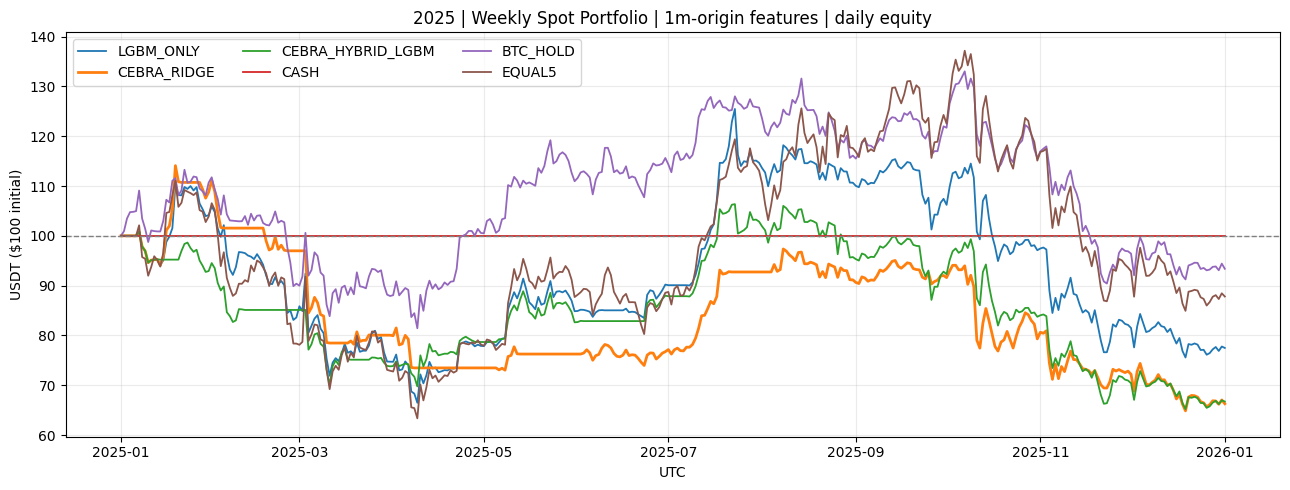

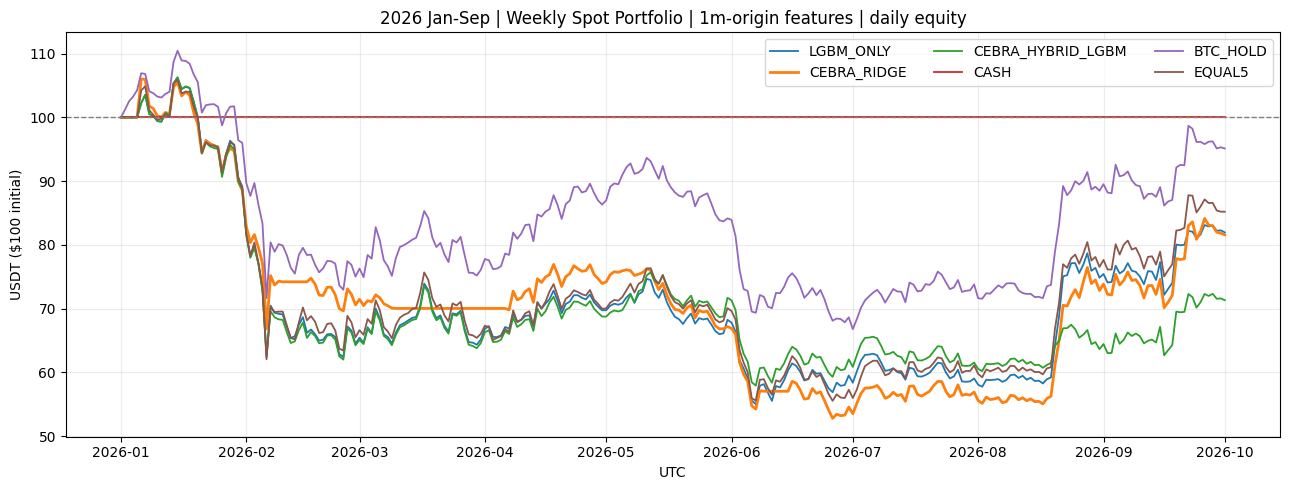

In [15]:
PERIODS = {
    '2025':('2025-01-01','2026-01-01'),
    '2026 Jan-Sep':('2026-01-01','2026-10-01')
}
ALL_REPORTS=[]; CURVES={}; TRADES={}
MODELS_TO_REPORT=FAMILIES+['CASH','BTC_HOLD','EQUAL5']
for label,(begin,end) in PERIODS.items():
    print('\n========= ',label,' =========')
    for name in MODELS_TO_REPORT:
        summary,curve,tx=run_portfolio(begin,end,name)
        summary['period']=label
        summary['selected_on_2024']=bool(name==WINNER)
        ALL_REPORTS.append(summary)
        CURVES[(label,name)]=curve
        TRADES[(label,name)]=tx
    selection=pd.DataFrame([x for x in ALL_REPORTS if x['period']==label])
    display(selection[['model','selected_on_2024','final_usdt','net_return',
                       'max_drawdown_daily','number_of_trades','transaction_cost_usdt',
                       'skipped_signals','mtm_proxy_days']].round(4))

REPORT=pd.DataFrame(ALL_REPORTS)
for period in PERIODS:
    plt.figure(figsize=(13,5))
    for name in MODELS_TO_REPORT:
        curve=CURVES[(period,name)]
        plt.plot(curve.index,curve.values,label=name,linewidth=2 if name==WINNER else 1.3)
    plt.axhline(100,color='gray',linestyle='--',linewidth=1)
    plt.title(f'{period} | Weekly Spot Portfolio | 1m-origin features | daily equity')
    plt.ylabel('USDT ($100 initial)'); plt.xlabel('UTC');plt.legend(ncol=3)
    plt.grid(alpha=.25);plt.tight_layout();plt.show()

## ۱۲) تشخیص کیفیت واقعی پیش‌بینی هفت‌روزه

علاوه بر سود، **MAE، دقت جهت و Spearman rank correlation بین پنج ارز** در روزهای تصمیم واقعی محاسبه می‌شود. اگر رتبه‌بندی ارزها ضعیف باشد، سود تصادفی یک بازه را نشانه پیش‌بینی قابل اتکا فرض نمی‌کنیم.

In [16]:
METRIC_ROWS=[]
for label,(begin,end) in PERIODS.items():
    begin=pd.Timestamp(begin,tz='UTC'); end=pd.Timestamp(end,tz='UTC')
    trade_days=pd.date_range(begin,end-pd.Timedelta(days=1),freq='D',tz='UTC')
    trade_days=trade_days[trade_days.weekday==WEEKDAY]
    for family in FAMILIES:
        per_day=[]
        for t in trade_days:
            pos=DATE_TO_POS.get(t-pd.Timedelta(days=1),-1)
            if pos<0:continue
            pred=PRED_DAILY[family][pos]
            true=Y_NUM[pos]
            mask=np.isfinite(pred)&np.isfinite(true)
            if mask.sum()<3: continue
            x=pred[mask];y=true[mask]
            rank=pd.Series(x).corr(pd.Series(y),method='spearman')
            per_day.append((float(np.mean(np.abs(x-y))),
                            float(np.mean((x>0)==(y>0))),float(rank)))
        if per_day:
            a=np.asarray(per_day,float)
            METRIC_ROWS.append({'period':label,'model':family,'weekly_samples':len(a),
                                'MAE_7d':float(np.nanmean(a[:,0])),
                                'direction_accuracy':float(np.nanmean(a[:,1])),
                                'mean_rank_spearman':float(np.nanmean(a[:,2]))})
METRICS=pd.DataFrame(METRIC_ROWS)
display(METRICS.round(4))

,period,model,weekly_samples,MAE_7d,direction_accuracy,mean_rank_spearman
0,2025,LGBM_ONLY,52,0.0724,0.4500,-0.1192
1,2025,CEBRA_RIDGE,52,0.0717,0.4423,-0.0846
2,2025,CEBRA_HYBRID_LGBM,52,0.0709,0.4808,-0.0673
3,2026 Jan-Sep,LGBM_ONLY,39,0.0629,0.4513,-0.0000
4,2026 Jan-Sep,CEBRA_RIDGE,39,0.0583,0.4821,-0.0974
5,2026 Jan-Sep,CEBRA_HYBRID_LGBM,39,0.0631,0.4513,-0.0179


## ۱۳) ارزش سبد در پایان هر ماه — سرمایه اولیه ۱۰۰ دلار

برای پیگیری مسیر سرمایه، وضعیت پایان هر ماه را از **منحنی ارزش روزانه** استخراج می‌کنیم: سرمایه در ابتدای روز اول ماه بعد، معادل تسویه دوره ماه قبل است. در این جدول می‌توان LightGBM-only را مستقیماً با مدل انتخاب‌شده و سبد مساوی مقایسه کرد.

In [17]:
MONTHLY_WEALTH=[]
for label,(begin,end) in PERIODS.items():
    begin=pd.Timestamp(begin,tz='UTC');end=pd.Timestamp(end,tz='UTC')
    for name in MODELS_TO_REPORT:
        equity=CURVES[(label,name)]
        month_boundaries=pd.date_range(begin+pd.offsets.MonthBegin(1),end,freq='MS',tz='UTC')
        for boundary in month_boundaries:
            if boundary in equity.index:
                MONTHLY_WEALTH.append({
                    'period':label,'month':(boundary-pd.Timedelta(days=1)).strftime('%Y-%m'),
                    'model':name,'capital_usdt':float(equity.loc[boundary]),
                    'cumulative_return':float(equity.loc[boundary]/START_CAPITAL-1.0)
                })
MONTHLY_WEALTH=pd.DataFrame(MONTHLY_WEALTH)
for period in PERIODS:
    print('\nMonth-by-month portfolio value:',period)
    display(MONTHLY_WEALTH[MONTHLY_WEALTH.period.eq(period)].pivot(
        index='month',columns='model',values='capital_usdt'
    ).round(2))
MONTHLY_WEALTH.to_csv(RESULTS/'monthly_capital_from_100usdt.csv',index=False)
print('Saved:',RESULTS/'monthly_capital_from_100usdt.csv')


Month-by-month portfolio value: 2025


model,BTC_HOLD,CASH,CEBRA_HYBRID_LGBM,CEBRA_RIDGE,EQUAL5,LGBM_ONLY
month,,,,,,
2025-01,109.30,100.0,93.50,108.90,105.21,104.79
2025-02,90.01,100.0,85.12,96.99,78.12,85.86
2025-03,88.08,100.0,73.85,79.94,72.76,74.71
2025-04,100.49,100.0,78.68,73.48,77.91,77.87
2025-05,111.60,100.0,82.68,76.26,88.16,84.91
2025-06,114.33,100.0,87.88,77.16,88.73,90.09
2025-07,123.53,100.0,101.89,92.74,110.47,113.59
2025-08,115.50,100.0,95.32,90.64,116.86,110.02
2025-09,121.70,100.0,92.30,91.61,122.52,106.21



Month-by-month portfolio value: 2026 Jan-Sep


model,BTC_HOLD,CASH,CEBRA_HYBRID_LGBM,CEBRA_RIDGE,EQUAL5,LGBM_ONLY
month,,,,,,
2026-01,89.70,100.0,81.49,82.88,81.64,81.86
2026-02,76.30,100.0,65.09,71.49,66.64,65.44
2026-03,77.79,100.0,66.31,70.05,67.33,66.85
2026-04,86.98,100.0,68.76,74.20,70.06,69.76
2026-05,83.93,100.0,71.30,66.93,69.65,67.83
2026-06,66.79,100.0,60.88,53.54,56.00,58.41
2026-07,71.64,100.0,60.55,55.60,59.78,58.08
2026-08,89.52,100.0,64.46,73.87,77.64,75.45
2026-09,95.12,100.0,71.33,81.58,85.21,81.96


Saved: /content/crypto_weekly_minute_v2/results/monthly_capital_from_100usdt.csv


## ۱۳) جزئیات معاملات، هزینه‌ها و فایل‌های خروجی

تمام خروجی‌ها داخل پوشه `results` در Google Drive ذخیره می‌شوند. فایل‌های مدل هر فصل هم داخل `models` نگهداری شده‌اند. برای مقایسه حتماً به **Max Drawdown روزانه** و هزینه معاملات توجه کن، نه فقط درصد سود.

In [18]:
VALIDATION_TABLE.to_csv(RESULTS/'validation_2024_model_selection.csv',index=False)
REPORT.to_csv(RESULTS/'weekly_portfolio_2025_2026.csv',index=False)
METRICS.to_csv(RESULTS/'weekly_prediction_diagnostics.csv',index=False)
for (label,name),tx in TRADES.items():
    safe_period=label.replace(' ','_').replace('-','_')
    tx.to_csv(RESULTS/f'{safe_period}_{name}_weekly_transactions.csv',index=False)
for (label,name),curve in CURVES.items():
    safe_period=label.replace(' ','_').replace('-','_')
    curve.to_csv(RESULTS/f'{safe_period}_{name}_daily_equity.csv',header=['equity'])

print('MODEL SELECTED BY 2024 VALIDATION:', WINNER)
print('RESULTS:',RESULTS)
print('MODEL CACHE:',MODEL_FILES)
print('PER-FOLD PREDICTION CACHE:',FOLD_CACHE)
print('\nDaily 1m history range per coin:')
for s in SYMBOLS:
    idx=DAILY[s].index[DAILY[s].available.eq(1)]
    print(s,idx[0].date(),'through',idx[-1].date())
print('\nDone. No run has promised real-world profits. History has been repeatedly analyzed; paper trade first.')

MODEL SELECTED BY 2024 VALIDATION: CEBRA_RIDGE
RESULTS: /content/crypto_weekly_minute_v2/results
MODEL CACHE: /content/crypto_weekly_minute_v2/models
PER-FOLD PREDICTION CACHE: /content/crypto_weekly_minute_v2/fold_predictions

Daily 1m history range per coin:
BTC 2017-08-17 through 2026-10-31
ETH 2017-08-17 through 2026-10-31
SOL 2020-08-11 through 2026-10-31
BNB 2017-11-06 through 2026-10-31
XRP 2018-05-04 through 2026-10-31

Done. No run has promised real-world profits. History has been repeatedly analyzed; paper trade first.


## نکات عملی و صحت‌سنجی

- **چرا ورودی مدل روزانه است با اینکه داده ۱دقیقه‌ای است؟** زیرا همه کندل‌های ۱دقیقه‌ای را پردازش می‌کنیم و رفتار درون‌روزی را به ویژگی‌هایی مثل Realized Volatility، فشار خرید آخر ساعت، جهش ۱دقیقه‌ای و تمرکز حجم تبدیل می‌کنیم. هدف در این نسخه بازده ۷روزه و تصمیم هفتگی است؛ آموزش CEBRA روی همه ۲۰+ میلیون کندل دقیقه‌ای در Colab رایگان سنگین و عمدتاً بی‌فایده برای این افق است.
- **چرا بازآموزی فصلی، نه هفتگی؟** هر سه ماه مدلی فقط با تاریخچه تا قبل از فصل جدید fit می‌شود؛ طی فصل سیگنال هر هفته با اطلاعات تازه تولید می‌شود. اجرای دوباره CEBRA هر هفته روی GPU رایگان بسیار سنگین‌تر است؛ بعداً می‌توانیم با همین ساختار فرکانس بازآموزی را تغییر دهیم.
- **چرا فقط نتایج ۲۰۲۴ برای انتخاب مدل است؟** چون ۲۰۲۵ و ۲۰۲۶ از قبل در این پروژه بررسی شده‌اند. انتخاب بهترین روش بر اساس همان دوره‌ها باعث بایاس انتخاب و بیش‌برازش به بک‌تست می‌شود.
- **محدودیت:** هزینه‌ها تخمینی، بدون بهره USDT، بدون حداقل سفارش/اسپرد دقیق یا اجرای زنده هستند. داده بایننس ممکن است روزهای ناقص داشته باشد که گزارش می‌شوند.
- **اگر Runtime قطع شد:** نوت‌بوک را دوباره از ابتدا اجرا کن؛ داده‌های ماهانه و فصل‌های تکمیل‌شده از Google Drive خوانده می‌شوند و مجدداً Train نمی‌شوند. برای تغییر ویژگی‌ها یا hyperparameterها، `CACHE_VERSION` را عوض کن تا cache قدیمی با مدل جدید اشتباه گرفته نشود.

منبع داده: [Binance Public Data](https://github.com/binance/binance-public-data) — کندل‌های Spot `1m` و تغییر واحد timestamp از ۲۰۲۵. راهنمای مدل: [CEBRA](https://cebra.ai/docs/api/sklearn/cebra.html) و [LightGBM](https://lightgbm.readthedocs.io/en/stable/Python-Intro.html).